# Classifier Guidance


In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F
import sklearn.metrics

from torch.utils.data import DataLoader
from utils import load_data

DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {DEVICE}")

Device: cpu


## Data

In [2]:
# load data
data_train, train_loader, X_train, y_train = load_data(
    data_dir_path="../data", 
    type="train", 
    task="classification"
)

data_val, val_loader, X_val, y_val = load_data(
    data_dir_path="../data", 
    type="val", 
    task="classification"
)

print('\n',repr(data_train),'\n',repr(data_val))

# train data, task: classification
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020])
# val data, task: classification
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001])

 ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129) 
 ProteinDataset(num_samples=2001, vocab_size=23, num_classes=3, max_length=129)


In [3]:
# check class balance per split before doing anything
# this way we're shure that each protein family is represented equally in training and val
from protgen.data import FAMILIES

counts = pd.DataFrame({"train": data_train.df.family.value_counts(),
                       "val": data_val.df.family.value_counts()}
                       ).loc[list(FAMILIES)]
print(counts)

        train  val
family            
AcyP     5340  667
HPr      5340  667
HU       5340  667


In [4]:
# prefix mask for loss calculation downstream
# mask PAD and BOS tokens, so that we don't include multiple copies of the full sequence
def prefix_mask(data):
    pos = torch.arange(data.max_length)
    lengths = torch.tensor(data.lengths)
    return (pos >= 1) & (pos <= lengths[:, None] + 1)   # (N, 129) bool, <EOS> included

mask_train, mask_val = prefix_mask(data_train), prefix_mask(data_val)

# expand Y to carry the family label at every position
# now each prefix can be used as its own training example
Y_train = y_train[:, None].expand(-1, data_train.max_length)
Y_val = y_val[:, None].expand(-1, data_val.max_length)

print(f"{int(mask_train.sum()):,} train prefixes from {len(data_train):,} sequences "
      f"({mask_train.sum() / len(data_train):.0f} each)")

1,537,909 train prefixes from 16,020 sequences (96 each)


## Encoding

In [5]:
# load the frozen RNN encoder config and weights
from protgen.models.rnn import RNNEncoder

VOCAB_SIZE, NUM_CLASSES = data_train.vocab_size, len(data_train.fam_to_idx)

ckpt = torch.load("../results/rnn.pt", map_location=DEVICE)
encoder = RNNEncoder(**ckpt["config"]).to(DEVICE)
encoder.load_state_dict(ckpt["state_dict"])
encoder.eval().requires_grad_(False)

RNNEncoder(
  (embed): Embedding(23, 64, padding_idx=0)
  (lstm): LSTM(64, 256, batch_first=True)
  (l_out): Linear(in_features=256, out_features=23, bias=False)
)

In [6]:
# use RNN to encode every sequence
@torch.no_grad()
def encode_all(X, bs=256):
    return torch.cat([encoder(X[i:i + bs].to(DEVICE))[1].cpu() for i in range(0, len(X), bs)])

H_train, H_val = encode_all(X_train), encode_all(X_val)
print(H_train.shape, H_val.shape)

torch.Size([16020, 129, 256]) torch.Size([2001, 129, 256])


## Classifier Training

In [7]:
# train two classification heads (one for generation and one for scoring)
# this way we don't get an optimistic evaluation
lr = 1e-3
batch_size = 256
epochs = 10

torch.manual_seed(0); head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
torch.manual_seed(1); eval_head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
opt = torch.optim.Adam([*head.parameters(), *eval_head.parameters()], lr=lr)

def masked_loss(model, H, Y, M):
    loss = F.cross_entropy(model(H).reshape(-1, NUM_CLASSES), Y.reshape(-1), reduction="none")
    return (loss * M.reshape(-1)).sum() / M.sum()

for epoch in range(epochs):
    perm = torch.randperm(len(H_train))
    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        H, Y, M = H_train[b].to(DEVICE), Y_train[b].to(DEVICE), mask_train[b].to(DEVICE)
        loss = masked_loss(head, H, Y, M) + masked_loss(eval_head, H, Y, M)   # disjoint params
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        val = masked_loss(head, H_val.to(DEVICE), Y_val.to(DEVICE), mask_val.to(DEVICE))
    print(f"epoch {epoch}  train {loss.item():.3f}  val {val.item():.3f}")

epoch 0  train 0.940  val 0.465
epoch 1  train 0.653  val 0.310
epoch 2  train 0.516  val 0.248
epoch 3  train 0.427  val 0.215
epoch 4  train 0.415  val 0.194
epoch 5  train 0.350  val 0.180
epoch 6  train 0.372  val 0.169
epoch 7  train 0.329  val 0.161
epoch 8  train 0.342  val 0.155
epoch 9  train 0.390  val 0.151


In [8]:
# predict on validation
with torch.no_grad():
    pred = head(H_val.to(DEVICE)).argmax(-1).cpu()

correct = (pred == Y_val) & mask_val
acc_by_len = correct.sum(0) / mask_val.sum(0).clamp(min=1)     # accuracy per prefix length
print(f"overall val accuracy {correct.sum() / mask_val.sum():.3f}")
print(sklearn.metrics.classification_report(Y_val[mask_val], pred[mask_val], target_names=FAMILIES))

overall val accuracy 0.942
              precision    recall  f1-score   support

        AcyP       0.94      0.94      0.94     63729
         HPr       0.93      0.92      0.93     64886
          HU       0.95      0.97      0.96     62589

    accuracy                           0.94    191204
   macro avg       0.94      0.94      0.94    191204
weighted avg       0.94      0.94      0.94    191204



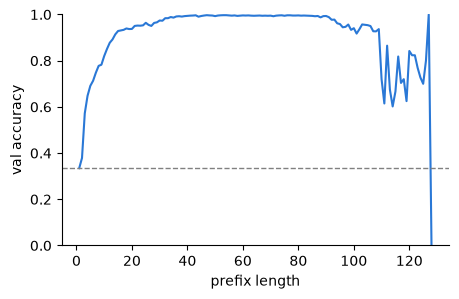

In [9]:
# accuracy vs. how much of the sequence the predictor has seen
ax = pd.Series(acc_by_len[1:].numpy(), index=range(1, data_train.max_length)).plot(
    figsize=(5, 3), color="#2a78d6", xlabel="prefix length", ylabel="val accuracy")
ax.axhline(1 / NUM_CLASSES, ls="--", c="grey", lw=1)   # chance
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)

In [10]:
# save both heads in results
torch.save({"head": head.state_dict(), "eval_head": eval_head.state_dict(),
            "hidden": H_train.shape[-1]}, "../results/classifier_head.pt")

## Guided generation

In [11]:
# for guided generation we reuse the sampler from phase 1 and only swap the logits it samples from
from protgen.models.rnn import sample

# guide generation towards HU family
TARGET = data_train.fam_to_idx["HU"]
SEED = 42
lambdas = [0.0, 1.0, 3.0, 10.0, 50.0, 100.0]

def guidance(lam):
    @torch.no_grad()
    def logit_fn(logits, state, i):
        B, V = logits.shape
        cand = torch.arange(V, device=logits.device).repeat(B)
        wide = tuple(s.repeat_interleave(V, dim=1) for s in state)
        _, h_next, _ = encoder.step(cand, wide)
        logp_y = F.log_softmax(head(h_next), -1)[:, TARGET].view(B, V)
        return logits + lam * logp_y
    return logit_fn

# run for different guidance strengths
for lam in lambdas:
    torch.manual_seed(SEED)
    seqs = sample(encoder, n=100, logit_fn=guidance(lam))   # lam=0 --> our unguided baseline
    pd.DataFrame({"sequence": seqs}).to_csv(
        f"../results/sequences/guided_lambda{lam:g}.csv", index=False)

In [12]:
# predicted family of finished sequences
# score with eval_head as stated above
@torch.no_grad()
def predict_family(seqs, model=None):
    X = torch.stack([data_train.encode(s) for s in seqs]).to(DEVICE)
    _, h = encoder(X)
    last = torch.tensor([len(s) + 1 for s in seqs], device=DEVICE)   # <BOS> + residues -> <EOS>
    return (model or eval_head)(h[torch.arange(len(seqs), device=DEVICE), last]).argmax(-1).cpu()

# sanity check on real proteins, should roughly recover the true families
real = data_val.df.sequence[:300]
print(pd.crosstab(data_val.df.family[:300], [FAMILIES[i] for i in predict_family(real)]))

col_0   AcyP  HPr   HU
family                
AcyP      96    1    0
HPr        5   81   11
HU         1    1  104


In [13]:
# target-family membership vs guidance strength
# and length distribution per guidance strength (making sure that strong lambda doesn't distort how long sequences get)
# should we plot this? Table is probs better in report?
membership = {}
rows = {}
lambdas = [0.0, 1.0, 3.0, 10.0, 50.0, 100.0]
CAP = data_train.max_length - 2

for lam in lambdas:
    seqs = pd.read_csv(f"../results/sequences/guided_lambda{lam:g}.csv").sequence
    L = seqs.str.len()

    membership[lam] = (predict_family(seqs) == TARGET).float().mean().item()
    rows[lam] = {"min": L.min(), "median": L.median(), "mean": L.mean(),
                 "max": L.max(), "frac_at_cap": (L >= CAP).mean()}

lengths_by_lam = pd.DataFrame(rows).T.round(1)
lengths_by_lam.index.name = "lambda"    

print(pd.Series(membership, name=f"fraction predicted {FAMILIES[TARGET]}"))

# real proteins of the target family, as a reference for what lengths should look like
ref = data_val.df.sequence[data_val.df.family == FAMILIES[TARGET]].str.len()
print(f"real {FAMILIES[TARGET]} (n={len(ref)}): "
      f"min {ref.min()}, median {ref.median():.0f}, mean {ref.mean():.1f}, max {ref.max()}\n")
print(lengths_by_lam)

0.0      0.23
1.0      0.61
3.0      0.97
10.0     0.97
50.0     0.95
100.0    0.93
Name: fraction predicted HU, dtype: float64
real HU (n=667): min 90, median 90, mean 92.8, max 125

         min  median   mean    max  frac_at_cap
lambda                                         
0.0     34.0    93.0   94.3  119.0          0.0
1.0     38.0    93.0   93.5  127.0          0.0
3.0     80.0    92.0   95.4  127.0          0.0
10.0    38.0    92.0   93.9  127.0          0.0
50.0    24.0   112.5  107.8  127.0          0.4
100.0   70.0   127.0  119.8  127.0          0.7
